# V07: DNS changes without a Spark restart

Measure workload continuity for a DNS edit that your deployment explicitly supports while compute is running.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## Advanced DNS objective and coverage limits

**Why run it:** Establish that supported Advanced DNS additions, updates and deletions reach an already-running workload without restarting or replacing its Spark application.

**Prerequisite:** Use service-resolvable public hostnames exercising explicit Advanced DNS mappings, rather than private-only hostnames handled through the default proxy.

**Current scope:** Run before/add/edit/delete/restored phases against real DNS changes. Retain DNS/mapping evidence, authenticated workload results, Spark application identity and independent lifecycle records throughout. Continued `SELECT 1` alone does not prove that the new destination became usable; an unchanged application display name alone does not exclude a restart.

Verify deployment support before starting. General workspace network-edit documentation says most network changes require stopped compute; this test applies only to the Advanced DNS operation your deployment supports live. If the UI requires a stop, record **BLOCKED** and do not bypass it. Older deployments/clusters can have an adoption prerequisite: confirm any one-time restart with the administrator, record it separately, then begin a fresh measured run. A restart during the measured change sequence fails the no-restart objective. Subsequent adoption does not retroactively turn a failed run into a pass.


## When do you need an Advanced DNS entry?

Advanced DNS lets you specify hostnames whose traffic needs to use your customer VCN. Private hostnames can already use customer DNS through the workspace's private connection.

| Your destination | How it is handled | What you need to do |
| --- | --- | --- |
| A hostname resolvable from the AIDP service network, whose traffic must use your customer VCN—for example, an S3 or public OCI service endpoint | An explicit Advanced DNS entry configures handling through the customer-network connection. | Add the actual hostname used by your application. Verify the required customer routes, security rules, and service permissions. |
| A private hostname, such as a private ADB hostname, that the AIDP service resolver cannot resolve | DNS resolution uses the private-endpoint DNS proxy and customer DNS context by default. | Verify customer DNS, private connectivity, and destination access rules. An Advanced DNS entry is not required solely because the hostname is private. |

A private endpoint does not by itself determine whether an entry is needed. Use the actual connection hostname and its resolution behavior. Validate the connection with an authenticated application operation.

Regional service-zone allowances are a separate policy consideration; they are not another resolution path or proof of an automatically inserted workspace entry. DNS configuration does not create routes or grant service permissions. Keep using the hostname for TLS identity checks, even when AIDP returns a mapped address.

**Before testing:** record the complete DNS/SCAN list, endpoint type, existing overrides and effective client configuration. A successful query alone does not identify the resolution mechanism. Do not delete a shared override to create a clean baseline. Use an approved clean test workspace or mark the default-path claim **INCOMPLETE** when provenance cannot be established.

For V04, first test the private endpoint without adding a database Advanced DNS entry. Keep that database configuration fixed while adding, replacing and deleting unrelated service-resolvable test hostnames, repeating the database query in each phase and after restoration. For V01–V03, V06 and V07, explicit-entry tests require service-resolvable hostnames; private-only names are unsuitable for demonstrating that provisioning mechanism. An unresolved owned name can remain a deliberately negative V06 test.

The [public workspace guide](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html) lists broad private-network scenarios; endpoint type and deployed resolver behavior determine whether an explicit entry is necessary. The [ADB private endpoint guide](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html) describes the destination's private access setup. Confirm your deployment's behavior with the administrator and retain independent evidence for the resolution path you claim.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Deployment capability | Confirm this particular DNS operation is supported without stopping compute in your deployment. Public documentation says most network changes require stopped clusters. If the UI requires a stop or the operation is unsupported, mark this case BLOCKED; do not bypass that requirement. |
| Network baseline | Use owned, service-resolvable public A/B hostnames suitable for explicit Advanced DNS provisioning and an existing working customer route, security rules and authenticated fixture. Private-only names exercise the default proxy path instead. Keep gateways, listener ports, identity and service policy unchanged across phases. |
| DNS evidence | Capture authoritative workspace mapping/readback for each phase. Record convergence time as observed; no universal propagation deadline is assumed. Do not copy a translated address from another workspace. |
| Runtime evidence | Use the same dedicated Spark session. Record application ID, SELECT 1, workload result and independent compute lifecycle evidence before/add/edit/delete/restored. A stable display name alone is insufficient. |


### Example network topology

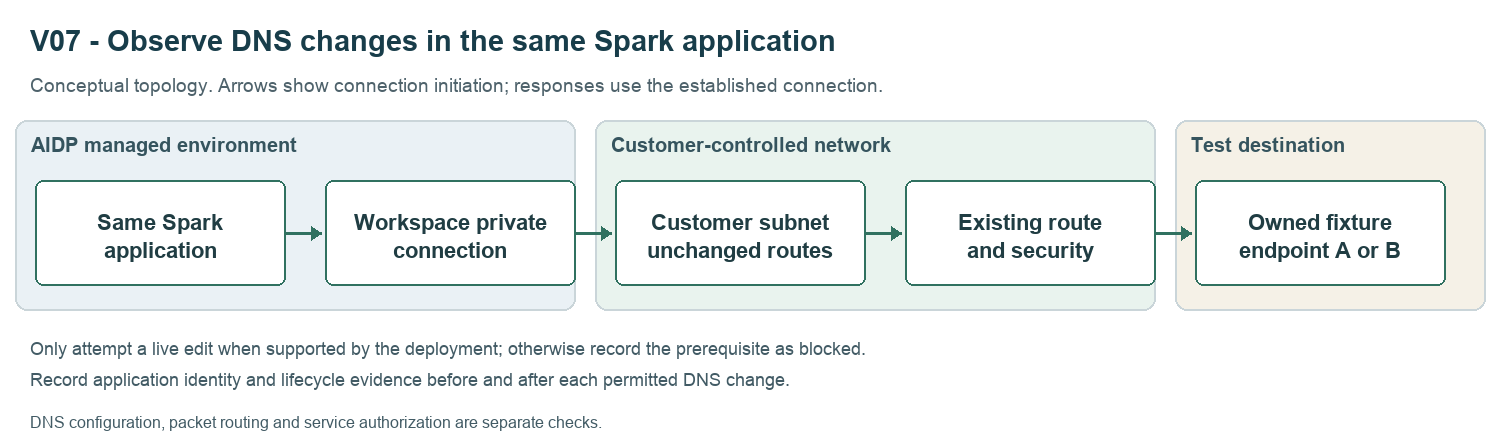

The diagram is illustrative; it does not prove the route taken by a request.


## IAM and network examples

Preparation templates only: replace every angle-bracket placeholder privately. An administrator prepares the approved resources; this notebook applies no policies or network changes.

### Separate operator, service and runtime permissions

The workspace operator needs access to the existing AIDP instance and the appropriate Workbench role/permissions to edit that workspace. Example OCI policies for an identity-domain group are:

```text
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to use ai-data-platforms in compartment <AIDP_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect vcns in compartment <VCN_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect subnets in compartment <SUBNET_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect network-security-groups in compartment <NSG_COMPARTMENT>
```

These statements allow instance access and network selection; they do not grant Workbench workspace-edit privileges, create infrastructure or authorize reads from data sources. Use the existing approved Workbench role. Policies belong in the relevant compartment or an ancestor with authority over that scope.

The platform also needs its private-network service permissions. The following adapts the documented AIDP network statements to explicit resource compartments and one instance:

```text
Allow any-user to manage vnics in compartment <VNIC_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use subnets in compartment <SUBNET_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use network-security-groups in compartment <NSG_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
```

Select the actual instance principal type (`aidataplatform` or the applicable legacy type), instance ID and placement compartments with your administrator. Retain the other existing service setup policies; this is not a full tenancy bootstrap. The runtime reading data can use a different identity from the operator or AIDP service: establish the connector's effective signer before choosing its policy subject.

Sources: [AIDP IAM policies](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/iam-policies-oracle-ai-data-platform.html), [AIDP workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html), [IAM policy scope](https://docs.oracle.com/en-us/iaas/Content/Security/Reference/iam_security_topic-IAM_Security_Policies.htm).

### Platform network baseline

The current workspace guide requires ingress from the customer VCN address range to all destination ports for private-network data access. An example baseline rule is **ingress; source CIDR `<CUSTOMER_VCN_CIDR>`; all protocols/ports; stateful**, in the security control selected for that workspace topology. Have the administrator reconcile this platform prerequisite with the approved design. The target-specific examples below are additional destination controls, not a replacement for platform rules. Do not use an internet-wide ingress rule.

Retain working DNS resolver access. With custom resolvers, permit UDP and TCP 53 to the approved resolver and configure forwarding/resolution in the customer network. Explicit Advanced DNS provisioning requires service-side resolvability; a successful customer-only lookup does not establish that prerequisite. Private ADB names unresolved by the service resolver use the default private DNS proxy/customer resolver path. Do not add them solely because they are private. Advanced DNS does not create a customer DNS zone, resolver endpoint, route, NAT gateway, service gateway or database listener. Use stateful connection rules in these examples; stateless designs need explicit return rules. Security lists and NSGs are additive, so check all applicable rules.

Source: [OCI security rules](https://docs.oracle.com/en-us/iaas/Content/Network/Concepts/securityrules.htm).

Reuse the V02 or V03 route, fixture and runtime read policy for the workload actually selected. Use service-resolvable public A/B hostnames for the explicit mapping changes. Keep permissions and network controls unchanged while measuring Advanced DNS add/edit/delete. The test adds no new service-access privilege.

Use your existing read-only access to independent lifecycle evidence. If OCI Logging holds the relevant lifecycle records, an example grant for the evidence reviewer is:

```text
Allow group <IDENTITY_DOMAIN>/<EVIDENCE_REVIEWERS> to read log-content in compartment <TEST_LOG_COMPARTMENT>
```

This reads available logs; it does not enable logging or guarantee Spark restart events are recorded. The administrator must select an authoritative lifecycle source for the deployment. Capture evidence privately. Any one-time adoption restart is a separate preparation event; do not include it in a passing no-restart sequence.

Source: [OCI Logging permissions](https://docs.oracle.com/en-us/iaas/Content/Identity/Reference/loggingpolicyreference.htm).

### Supporting pattern: V02

### How the IAM restriction works

| IAM element | What it checks | This example |
| --- | --- | --- |
| Resource principal | **Who signed the request?** | The AIDP instance resource identity. |
| Dynamic group | **Is that resource a member?** | `aidp_v02_reader` contains the selected AIDP instance. |
| Network Source | **Where did the request originate?** | `aidp_v02_vcn` contains the customer VCN and allowed subnet range. |
| Policy | **What may this caller do, from that source?** | Read the named bucket only when the Network Source matches. |

The dynamic group and Network Source are independent IAM objects. The policy connects them. Neither object grants access by itself. Putting an AIDP resource in the dynamic group does not put its requests in the allowed network.

For this grant, **caller is a group member AND bucket matches AND source matches** must all be true. IAM evaluates the source condition when Object Storage authorizes the request. It uses the request's VCN/source-address context through the service gateway; the notebook does not send a Network Source name as a credential.

A dynamic group is the identity mechanism chosen for this walkthrough. A policy that directly matches a resource principal can also authorize it without a dynamic group; do not add that alternative grant alongside this test policy.

### Before you begin

Use an existing private-network workspace and a small private test bucket. Have the AIDP administrator confirm that the native `oci://` reader uses the AIDP instance resource principal. A dynamic group does not change the reader's authentication mode. If the reader uses a user credential, stop and resolve that setup before using this resource-principal walkthrough.

Record:

| Value | Obtain from |
| --- | --- |
| `<AIDP_RESOURCE_ID>` | AIDP instance details: its resource OCID, not the workspace or cluster UUID. |
| `<IAM_DOMAIN>` | Identity domain where the dynamic group will be created. |
| `<BUCKET_COMPARTMENT_ID>`, `<BUCKET_NAME>`, namespace | Object Storage bucket details. |
| `<CUSTOMER_VCN_ID>`, `<SOURCE_SUBNET_CIDR>` | The VCN and customer-side source subnet used by the workspace private connection. |
| Object key, size and expected rows | An existing CSV fixture of at most 64 KiB, uploaded by the bucket owner. |

### IAM setup

An existing IAM administrator completes these three steps before the tester runs the notebook.

#### 1. Create the dynamic group: who may read

In **Identity & Security > Domains > your domain > Dynamic groups**, create `aidp_v02_reader`. In a tenancy without identity domains, open **Identity & Security > Dynamic Groups**. Enter this matching rule, replacing the placeholder:

```text
ALL {resource.id = '<AIDP_RESOURCE_ID>'}
```

Use `resource.id` for the AIDP resource, not a Compute instance matching rule. This selects one resource; it does not include every resource in the compartment.

#### 2. Create the Network Source: where requests may originate

In the tenancy's **home region**, open **Identity & Security > Network Sources > Create Network Source**:

| Field | Value |
| --- | --- |
| Name | `aidp_v02_vcn` |
| Network type | **Virtual Cloud Network** |
| VCN OCID | `<CUSTOMER_VCN_ID>` |
| IP address/CIDR | `<SOURCE_SUBNET_CIDR>`, such as `10.20.1.0/24` in an illustrative network |

Add no public IP range for this test. The VCN ID and source range form a pair: the same IP range in a different VCN does not match. Do not enter the Object Storage destination IP.

#### 3. Create the policy: permission plus source restriction

Open **Identity & Security > Policies** in the bucket compartment or an authorized ancestor. Create a policy using the manual editor:

```text
Allow dynamic-group <IAM_DOMAIN>/aidp_v02_reader to read objects in compartment id <BUCKET_COMPARTMENT_ID> where all {target.bucket.name='<BUCKET_NAME>', request.networkSource.name='aidp_v02_vcn'}
Allow dynamic-group <IAM_DOMAIN>/aidp_v02_reader to read buckets in compartment id <BUCKET_COMPARTMENT_ID> where all {target.bucket.name='<BUCKET_NAME>', request.networkSource.name='aidp_v02_vcn'}
```

For a tenancy without identity domains, use `dynamic-group aidp_v02_reader`. The first statement permits object reads/listing; the second permits bucket metadata checks. No write grant is needed.

Review all effective grants for this resource and bucket, including inherited policies and other dynamic-group memberships. An additional unconditional allow can bypass this restriction. Choose an isolated test bucket if existing grants cannot be safely scoped. Allow IAM and dynamic-group membership changes to propagate, then keep these definitions unchanged throughout the test.

### Network setup

| Component | Required configuration |
| --- | --- |
| Workspace | Existing private connection to the customer VCN/subnet recorded above; platform private-network prerequisites already satisfied. |
| Service gateway | Enabled Object Storage service, or All Services label including Object Storage, in this same region. |
| Source subnet route | Destination type **Service**, matching regional service label, target the service gateway. |
| Egress controls | Stateful TCP 443 to the regional service label through the applicable subnet/NSG/firewall rules. |

Expected application path: **AIDP -> workspace private connection -> customer subnet -> service gateway -> Object Storage**. The service-gateway path supplies the customer VCN source context needed by this policy.

### Supporting pattern: V03

### Runtime read policy

For an existing dynamic group matching the connector's signer, grant access to the remote fixture bucket:

```text
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read objects in compartment <REMOTE_DATA_COMPARTMENT> where target.bucket.name='<REMOTE_TEST_BUCKET>'
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read buckets in compartment <REMOTE_DATA_COMPARTMENT> where target.bucket.name='<REMOTE_TEST_BUCKET>'
```

If the signer is a user, use `group <IDENTITY_DOMAIN>/<FIXTURE_READERS>` as the subject instead. Grant equivalent access to the separate in-region control fixture if it is not already authorized. These examples assume one tenancy; cross-tenancy access needs its own endorsement/admission arrangement. IAM permission does not configure a regional endpoint or establish a route.

### Route and security example

| Control | Example |
| --- | --- |
| Region A customer subnet | Default route `0.0.0.0/0` to existing `<NAT_GATEWAY_ID>` or approved egress appliance. |
| Remote destination | Region B public Object Storage endpoint, stateful TCP 443 to its approved ranges through the firewall/NSG. |
| Regional service route | Region A service gateway remains the Region A route; it cannot supply the Region B path. |
| Client and DNS | Explicit Region B bucket endpoint and its exact Advanced DNS FQDN where required; use a fresh client to avoid a cached Region A endpoint. |

If the remote bucket requires a Network Source, its restriction must match the actual approved egress context. The V02 customer-VCN/service-gateway condition is not automatically applicable to this NAT path. Do not remove a restriction just to pass the test.

Sources: [Object Storage policy examples](https://docs.oracle.com/en/solutions/oci-object-storage-modernization/configure-tenancy.html), [NAT gateway](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/NATgateway.htm), [HDFS endpoint configuration](https://docs.oracle.com/en-us/iaas/Content/API/SDKDocs/hdfsconnector.htm).


## Test procedure

1. First verify the capability prerequisite and capture the before phase.
2. For each permitted add/edit/delete operation, keep the same session and record the reader, DNS mapping and application identity.
3. Capture lifecycle events across the entire run, including any stop/start/replacement.
4. Restore the original configuration. If a prerequisite adoption restart is needed, handle it outside this measured run and start a separate test afterward.

**Acceptance:** Actual DNS changes converge, every workload phase passes, the Spark application is unchanged and lifecycle evidence shows no restart. Otherwise record the observed failure or prerequisite.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V07': 'DNS changes without a Spark restart'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def fixture_read(spark, cfg):
    """Bounded CSV check; connector options apply to this reader, not globally."""
    for key in ('uri', 'endpoint', 'expected_rows'):
        if not cfg.get(key):
            raise Prerequisite('Missing fixture ' + key)
    uri, endpoint = (cfg['uri'], cfg['endpoint'])
    if '?' in uri or '#' in uri or '?' in endpoint or ('#' in endpoint):
        raise Prerequisite('Use unsigned fixture and endpoint references')
    parsed_endpoint = urlsplit(endpoint if '://' in endpoint else 'https://' + endpoint)
    if parsed_endpoint.username is not None or parsed_endpoint.password is not None:
        raise Prerequisite('Endpoint must not contain embedded credentials')
    if not parsed_endpoint.hostname:
        raise Prerequisite('Missing endpoint hostname')
    if uri.startswith('s3a://') and '@' in uri.split('://', 1)[1].split('/', 1)[0]:
        raise Prerequisite('S3 URI must not contain embedded credentials')
    expected = cfg['expected_rows']
    if not isinstance(expected, list) or not 1 <= len(expected) <= 100:
        raise Prerequisite('Supply 1 to 100 expected synthetic CSV rows')
    size = cfg.get('fixture_size_bytes')
    if not isinstance(size, int) or isinstance(size, bool) or (not 0 < size <= 65536):
        raise Prerequisite('Verify fixture size is between 1 byte and 64 KiB')
    reader = spark.read.option('header', 'true').option('inferSchema', 'false')
    if uri.startswith('s3a://'):
        if not cfg.get('region'):
            raise Prerequisite('Missing AWS region')
        reader = reader.option('fs.s3a.endpoint', endpoint).option('fs.s3a.endpoint.region', cfg['region'])
    elif uri.startswith('oci://'):
        authority = uri.split('://', 1)[1].split('/', 1)[0]
        if authority.count('@') != 1:
            raise Prerequisite('OCI URI must specify bucket@namespace')
        bucket, namespace = authority.split('@')
        reader = reader.option('fs.oci.client.hostname.' + bucket + '.' + namespace, endpoint)
    else:
        raise Prerequisite('Use s3a:// or oci://')
    rows = reader.csv(uri).limit(len(expected) + 1).collect()
    actual = [r.asDict() for r in rows]
    assert collections.Counter(map(canonical, actual)) == collections.Counter(map(canonical, expected)), 'Fixture content mismatch'
    return {'rows': len(actual), 'fixture_assertion': 'exact row multiset', 'configured_endpoint': endpoint}

def adb_read(spark, cfg, runtime):
    """Use an existing catalog connection or an existing wallet ZIP.

    runtime carries secrets in memory only and is never included in results.
    No wallet is generated/copied; provide a supported existing ZIP or catalog.
    """
    if not cfg.get('expected_instance'):
        raise Prerequisite('Missing expected database identity')
    reader = spark.read.format('aidataplatform').option('type', 'ORACLE_ALH').option('schema', 'SYS').option('table', 'DUAL').option('pushdown.sql', "SELECT sys_context('userenv','instance_name') AS INSTANCE_NAME FROM dual").option('login.timeout.seconds', '20')
    if cfg.get('catalog_id'):
        reader = reader.option('catalog.id', cfg['catalog_id'])
    else:
        if not cfg.get('wallet_zip') or not cfg.get('tns') or (not cfg.get('user')):
            raise Prerequisite('Existing catalog or wallet ZIP/TNS/user required')
        password = runtime.get('adb_password')
        if not password:
            raise Prerequisite('ADB password is missing from runtime context')
        reader = reader.option('wallet.path', cfg['wallet_zip']).option('tns', cfg['tns']).option('user.name', cfg['user']).option('password', password)
    rows = reader.load().limit(2).collect()
    assert len(rows) == 1, 'Identity query must return one row'
    assert str(rows[0][0]) == cfg['expected_instance'], 'Unexpected database identity'
    return {'rows': 1, 'identity_matches': True, 'transport_claim': 'Authenticated query; mTLS not independently established'}

def run_case(case, cfg, spark=None, runtime=None, live=False, phase='baseline', fixture_role='primary'):
    if case not in CASE_NAMES:
        raise ValueError('Unknown case')
    if fixture_role not in ('primary', 'local_control') or (fixture_role == 'local_control' and case != 'V03'):
        raise ValueError('Local control is supported only for V03')
    result = {'case': case, 'name': CASE_NAMES[case], 'utc': utc(), 'phase': phase, 'workspace_label': cfg.get('workspace_label'), 'compute_label': cfg.get('compute_label'), 'checks': {}, 'origin': 'harness'}
    checks = result['checks']

    def check(name, action):
        started = time.monotonic()
        try:
            checks[name] = {'status': 'PASS', 'detail': action()}
        except Prerequisite as exc:
            checks[name] = {'status': 'BLOCKED', 'reason': str(exc)}
        except Exception as exc:
            checks[name] = {'status': 'FAIL', 'error_type': type(exc).__name__}
        checks[name]['elapsed_seconds'] = round(time.monotonic() - started, 3)
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    if spark is None:
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Existing Spark session required'}
        return result
    if not cfg.get('workspace_label') or not cfg.get('compute_label'):
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Record workspace and compute labels'}
        return result

    def spark_control():
        value = spark.sql('SELECT 1').collect()[0][0]
        assert value == 1, 'Spark control query returned unexpected result'
        return {'select_1': value, 'application_id': spark.sparkContext.applicationId}
    check('spark_control', spark_control)
    host = cfg.get('hostname') or endpoint_host(cfg.get('endpoint', ''))
    if not host:
        checks['dns'] = {'status': 'BLOCKED', 'reason': 'Missing exact hostname'}
    else:
        check('dns', lambda: {'addresses': sorted({a[4][0] for a in socket.getaddrinfo(host, cfg.get('port', 443), type=socket.SOCK_STREAM)})})
        if cfg.get('probe_tcp', False):

            def tcp():
                with socket.create_connection((host, cfg.get('port', 443)), timeout=5):
                    return {'connected': True, 'tls_verified': False}
            check('tcp', tcp)
        else:
            checks['tcp'] = {'status': 'NOT_RUN'}
    if cfg.get('kind') == 'csv':
        check('functional', lambda: fixture_read(spark, cfg))
    elif cfg.get('kind') == 'adb':
        check('functional', lambda: adb_read(spark, cfg, runtime or {}))
        checks['mtls'] = {'status': 'BLOCKED', 'reason': 'Requires separate effective-descriptor and client-certificate evidence'}
    else:
        checks['functional'] = {'status': 'BLOCKED', 'reason': 'Configure kind=csv or adb'}
    checks['source_path'] = {'status': 'BLOCKED', 'reason': 'Independent path evidence required; successful read is insufficient'}
    return result

def evaluate_evidence(case, evidence):
    """Validate explicitly supplied Workbench snapshots; never modify Workbench.

    These assertions check recorded observations. External source-path, private
    endpoint and mTLS claims always require human evidence review.
    """
    result = {'case': case, 'utc': utc(), 'origin': 'supplied evidence', 'checks': {}}
    checks = result['checks']
    if not evidence.get('evidence_ref'):
        checks['evidence'] = {'status': 'BLOCKED', 'reason': 'Missing evidence artifact reference'}
        return result

    def test(name, condition):
        checks[name] = {'status': 'PASS' if condition else 'FAIL'}
    before = evidence.get('before')
    restored = evidence.get('restored')
    phases = evidence.get('phases', [])
    expected_phases = {'before', 'after_add', 'after_edit', 'after_delete', 'restored'}
    test('complete_phases', {p.get('phase') for p in phases} == expected_phases and len(phases) == 5)
    test('functional_each_phase', bool(phases) and all((p.get('functional') == 'PASS' and p.get('operation_evidence_ref') for p in phases)))
    test('restored_baseline', isinstance(before, dict) and same(before, restored))
    snapshots = {p.get('phase'): p.get('configuration_snapshot') for p in phases}
    test('configuration_change_exercised', all((isinstance(v, dict) for v in snapshots.values())) and all((k in snapshots for k in expected_phases)) and (not same(snapshots.get('before'), snapshots.get('after_add'))) and (not same(snapshots.get('after_add'), snapshots.get('after_edit'))) and same(snapshots.get('before'), snapshots.get('after_delete')) and same(snapshots.get('before'), snapshots.get('restored')))
    ids = {p.get('application_id') for p in phases}
    test('same_spark_application', len(ids) == 1 and None not in ids and ('' not in ids))
    test('no_restart_events', evidence.get('restart_count') == 0 and bool(evidence.get('lifecycle_evidence_ref')))
    test('dns_each_phase', bool(phases) and all((p.get('dns_addresses') and p.get('expected_dns_addresses') and p.get('mapping_evidence_ref') and (set(p['dns_addresses']) == set(p['expected_dns_addresses'])) for p in phases)))
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V07'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443,
 'kind': 'csv',
 'uri': '',
 'endpoint': '',
 'region': '',
 'workspace_region': '',
 'fixture_size_bytes': 0,
 'expected_rows': [{'id': '1', 'label': 'alpha'}, {'id': '2', 'label': 'beta'}]}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


## Run a workload phase

Use the same identity and client before and after a supported change. Only set RUN_LIVE=True when prerequisites are ready. For subsequent phases, change PHASE and rerun this cell without reinitializing RESULTS. The runtime password hook reads an already-provisioned environment variable; it never prints its value. The sample does not configure the S3A credential provider or install connector libraries.


In [ ]:
import os
RUNTIME = {}
if os.environ.get("ADB_PASSWORD"):
    RUNTIME["adb_password"] = os.environ["ADB_PASSWORD"]
result = run_case(CASE_ID, CONFIG, spark=globals().get("spark"), runtime=RUNTIME, live=RUN_LIVE, phase=PHASE)
result["acceptance"] = summarize(result)
RESULTS.append(result)
print(json.dumps(result, indent=2))


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None,
 'before': None,
 'restored': None,
 'phases': [{'phase': 'before',
             'functional': None,
             'operation_evidence_ref': None,
             'application_id': None,
             'configuration_snapshot': None,
             'instance': None,
             'dns_addresses': [],
             'expected_dns_addresses': [],
             'mapping_evidence_ref': None},
            {'phase': 'after_add',
             'functional': None,
             'operation_evidence_ref': None,
             'application_id': None,
             'configuration_snapshot': None,
             'instance': None,
             'dns_addresses': [],
             'expected_dns_addresses': [],
             'mapping_evidence_ref': None},
            {'phase': 'after_edit',
             'functional': None,
             'operation_evidence_ref': None,
             'application_id': None,
             'configuration_snapshot': None,
             'instance': None,
             'dns_addresses': [],
             'expected_dns_addresses': [],
             'mapping_evidence_ref': None},
            {'phase': 'after_delete',
             'functional': None,
             'operation_evidence_ref': None,
             'application_id': None,
             'configuration_snapshot': None,
             'instance': None,
             'dns_addresses': [],
             'expected_dns_addresses': [],
             'mapping_evidence_ref': None},
            {'phase': 'restored',
             'functional': None,
             'operation_evidence_ref': None,
             'application_id': None,
             'configuration_snapshot': None,
             'instance': None,
             'dns_addresses': [],
             'expected_dns_addresses': [],
             'mapping_evidence_ref': None}],
 'restart_count': None,
 'lifecycle_evidence_ref': None}


In [ ]:
if RUN_EVIDENCE_CHECKS:
    observed = evaluate_evidence(CASE_ID, EVIDENCE)
    observed["acceptance"] = summarize(observed)
    RESULTS.append(observed)
    print(json.dumps(observed, indent=2))
else:
    print("Evidence assertions NOT_RUN; capture real observations first.")


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
